# 02 — Multi-Criteria Decision Making (MCDM): TOPSIS Murni & Bobot Entropi

**Proyek:** GeoPulse-id — Sistem Pendukung Keputusan Berbasis Dashboard Analitik dengan Integrasi K-Means Clustering dan TOPSIS untuk Prioritas Mitigasi Banjir di DKI Jakarta.  
**Cakupan:** 42 Kecamatan di DKI Jakarta (Kecamatan daratan Jakarta; Kepulauan Seribu tidak diikutkan karena karakteristik kepulauan).  
**Output:** `Data/topsis_result.csv` (digunakan sebagai input untuk clustering K-Means di tahap berikutnya).

---

## Ringkasan Konsep & Metodologi

Sistem ini mengadopsi kerangka kerja risiko bencana internasional (*Disaster Risk Framework*):

$$\text{Risiko Banjir} = \frac{\text{Bahaya (Hazard)} \times \text{Kerentanan (Vulnerability)}}{\text{Kapasitas (Capacity)}}$$

### Prinsip Dasar TOPSIS Murni
**TOPSIS** (*Technique for Order of Preference by Similarity to Ideal Solution*) didasarkan pada konsep bahwa alternatif yang menjadi **prioritas darurat tertinggi** harus memiliki jarak terdekat dari **Solusi Ideal Positif ($A^+$)** dan jarak terjauh dari **Solusi Ideal Negatif ($A^-$)**:
* **Solusi Ideal Positif ($A^+$)**: Kondisi bencana terparah (Bahaya & Kerentanan maksimum, Kapasitas minimum).
* **Solusi Ideal Negatif ($A^-$)**: Kondisi paling aman (Bahaya & Kerentanan minimum, Kapasitas maksimum).

### 5 Langkah Perhitungan Matematis TOPSIS Murni:
1. **Normalisasi Vektor:**
   $$r_{ij} = \frac{x_{ij}}{\sqrt{\sum_{k=1}^{m} x_{kj}^2}}$$
2. **Matriks Ternormalisasi Terbobot:**
   $$v_{ij} = w_j \times r_{ij}$$
3. **Solusi Ideal Positif ($A^+$) dan Solusi Ideal Negatif ($A^-$):**
   - Kriteria **Benefit** (Bahaya & Kerentanan): $A_j^+ = \max_i(v_{ij}), \quad A_j^- = \min_i(v_{ij})$
   - Kriteria **Cost** (Kapasitas): $A_j^+ = \min_i(v_{ij}), \quad A_j^- = \max_i(v_{ij})$
4. **Jarak Euclidean ke Solusi Ideal:**
   $$D_i^+ = \sqrt{\sum_{j=1}^{n} (v_{ij} - A_j^+)^2}, \quad D_i^- = \sqrt{\sum_{j=1}^{n} (v_{ij} - A_j^-)^2}$$
5. **Skor Kedekatan Relatif ($C_i$) & Perankingan:**
   $$C_i = \frac{D_i^-}{D_i^+ + D_i^-}$$
   - Nilai $C_i \in [0, 1]$. Semakin mendekati 1, semakin tinggi risiko dan urgensi mitigasi banjir di kecamatan tersebut.

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

ROOT = Path("..")
DATA = ROOT / "Data"
RAW = DATA / "Raw"
INT = DATA / "interim"

print("Direktori data:", DATA.resolve())

Direktori data: C:\Sem5_Projects\Geopulse-id\Data


## 1. Memuat Master Dataset & Pemfilteran Wilayah

Kita membaca `Data/dki_master.csv` yang telah disiapkan pada tahap `01_data.ipynb`.  
Kecamatan di wilayah Kabupaten Administrasi Kepulauan Seribu dipisahkan agar analisis fokus pada 42 kecamatan daratan Jakarta yang memiliki dinamika banjir limpasan sungai dan rob pantai.

In [2]:
master_raw = pd.read_csv(DATA / "dki_master.csv")
print(f"Total kecamatan awal: {len(master_raw)}")

# Filter 42 kecamatan (keluarkan Kepulauan Seribu)
is_seribu = master_raw.wilayah.str.contains("SERIBU", na=False) | master_raw.kecamatan.str.contains("SERIBU", na=False)
df_kec = master_raw[~is_seribu].copy().reset_index(drop=True)

print(f"Total kecamatan dianalisis: {len(df_kec)}")
display(df_kec[["kecamatan", "wilayah", "penduduk", "luas_km2", "kepadatan_jiwa_km2", "kejadian_per_tahun"]].head())

Total kecamatan awal: 44
Total kecamatan dianalisis: 42


,kecamatan,wilayah,penduduk,luas_km2,kepadatan_jiwa_km2,kejadian_per_tahun
0,CENGKARENG,JAKARTA BARAT,612880.43,27.93,21943.445399,15.875
1,GROGOL PETAMBURAN,JAKARTA BARAT,246399.94,11.46,21500.867365,6.625
2,KALI DERES,JAKARTA BARAT,415566.68,29.08,14290.463549,7.250
3,KEBON JERUK,JAKARTA BARAT,340367.96,16.64,20454.805288,16.250
4,KEMBANGAN,JAKARTA BARAT,304019.61,24.64,12338.458198,10.500


## 2. Penetapan Kriteria & Arah (Benefit vs Cost)

Berdasarkan framework **Bahaya (Hazard) - Kerentanan (Vulnerability) - Kapasitas (Capacity)**:
* **Bahaya (Benefit):**
  1. `frek_tahun_banjir`: Proporsi tahun terjadinya banjir (frekuensi temporal jangka panjang).
  2. `bulan_banjir_per_tahun`: Rata-rata jumlah bulan berbeda yang mengalami banjir per tahun.
  3. `kejadian_per_tahun`: Rata-rata frekuensi kejadian banjir per tahun.
  4. `tinggi_max_cm`: Ketinggian genangan air maksimum tercatat (keparahan fisik).
  5. `lama_hari_mean`: Durasi rata-rata banjir bertahan (hari).
  6. `jiwa_per_1000`: Jumlah warga terdampak per 1.000 penduduk (dampak kemanusiaan).
* **Kerentanan (Benefit):**
  7. `kepadatan_jiwa_km2`: Kepadatan penduduk (konsentrasi paparan populasi).
* **Kapasitas (Cost):**
  8. `n_alat_dini`: Jumlah alat peringatan dini banjir (EWS BPBD) yang terpasang di kecamatan tersebut (kemampuan deteksi dan kesiapsiagaan).

In [3]:
criteria_meta = {
    "frek_tahun_banjir":      {"dimensi": "Bahaya",      "type": "benefit", "satuan": "proporsi (0-1)", "desc": "Proporsi tahun terjadi banjir"},
    "bulan_banjir_per_tahun": {"dimensi": "Bahaya",      "type": "benefit", "satuan": "bulan/tahun",    "desc": "Rata-rata bulan banjir per tahun"},
    "kejadian_per_tahun":     {"dimensi": "Bahaya",      "type": "benefit", "satuan": "kejadian/tahun", "desc": "Frekuensi banjir tahunan"},
    "tinggi_max_cm":          {"dimensi": "Bahaya",      "type": "benefit", "satuan": "cm",             "desc": "Ketinggian genangan maksimal"},
    "lama_hari_mean":         {"dimensi": "Bahaya",      "type": "benefit", "satuan": "hari",           "desc": "Rata-rata durasi genangan"},
    "jiwa_per_1000":          {"dimensi": "Bahaya",      "type": "benefit", "satuan": "jiwa/1000 pddk", "desc": "Penduduk terdampak per 1000 warga"},
    "kepadatan_jiwa_km2":     {"dimensi": "Kerentanan",  "type": "benefit", "satuan": "jiwa/km2",       "desc": "Kepadatan penduduk wilayah"},
    "n_alat_dini":            {"dimensi": "Kapasitas",   "type": "cost",    "satuan": "unit EWS",       "desc": "Jumlah alat peringatan dini (EWS)"}
}

crit_df = pd.DataFrame(criteria_meta).T
crit_cols = list(criteria_meta.keys())
crit_types = [criteria_meta[c]["type"] for c in crit_cols]

display(crit_df)

# Matriks keputusan X (42 x 8)
X = df_kec[crit_cols].values.astype(float)
print(f"Dimensi Matriks Keputusan X: {X.shape[0]} kecamatan x {X.shape[1]} kriteria")
df_kec[crit_cols].describe().T[["mean", "std", "min", "50%", "max"]].round(2)

,dimensi,type,satuan,desc
frek_tahun_banjir,Bahaya,benefit,proporsi (0-1),Proporsi tahun terjadi banjir
bulan_banjir_per_tahun,Bahaya,benefit,bulan/tahun,Rata-rata bulan banjir per tahun
kejadian_per_tahun,Bahaya,benefit,kejadian/tahun,Frekuensi banjir tahunan
tinggi_max_cm,Bahaya,benefit,cm,Ketinggian genangan maksimal
lama_hari_mean,Bahaya,benefit,hari,Rata-rata durasi genangan
jiwa_per_1000,Bahaya,benefit,jiwa/1000 pddk,Penduduk terdampak per 1000 warga
kepadatan_jiwa_km2,Kerentanan,benefit,jiwa/km2,Kepadatan penduduk wilayah
n_alat_dini,Kapasitas,cost,unit EWS,Jumlah alat peringatan dini (EWS)


Dimensi Matriks Keputusan X: 42 kecamatan x 8 kriteria


,mean,std,min,50%,max
frek_tahun_banjir,0.84,0.22,0.25,1.00,1.00
bulan_banjir_per_tahun,2.99,2.09,0.25,2.56,8.12
kejadian_per_tahun,7.46,5.89,0.50,6.62,22.62
tinggi_max_cm,177.62,86.93,40.00,165.00,400.00
lama_hari_mean,1.64,0.76,0.00,1.60,4.26
jiwa_per_1000,14.29,18.47,0.00,7.51,82.71
kepadatan_jiwa_km2,21184.53,11029.30,8824.66,19357.48,61408.89
n_alat_dini,0.31,0.60,0.00,0.00,2.00


## 3. Pembobotan Kriteria: Metode Shannon Entropy

**Shannon Entropy** adalah metode pembobotan objektif yang mengukur ketidakpastian informasi dalam data:
1. Normalisasi proporsi probabilitas:
   $$p_{ij} = \frac{x_{ij}}{\sum_{i=1}^{m} x_{ij}}$$
2. Nilai entropi tiap kriteria ($k = \frac{1}{\ln(m)}$):
   $$e_j = -k \sum_{i=1}^{m} p_{ij} \ln(p_{ij})$$
3. Derajat divergensi informasi (dispersi):
   $$d_j = 1 - e_j$$
4. Bobot objektif kriteria:
   $$w_j = \frac{d_j}{\sum_{j=1}^{n} d_j}$$

*Kriteria dengan variasi data yang tinggi antar kecamatan akan memiliki nilai entropi lebih rendah ($e_j$), divergensi ($d_j$) lebih tinggi, sehingga memperoleh bobot ($w_j$) lebih besar.*

,Dimensi,Tipe,Bobot_Entropi,Bobot_Equal,Bobot_Expert
frek_tahun_banjir,Bahaya,benefit,0.0131,0.125,0.10
bulan_banjir_per_tahun,Bahaya,benefit,0.0793,0.125,0.15
kejadian_per_tahun,Bahaya,benefit,0.0979,0.125,0.15
tinggi_max_cm,Bahaya,benefit,0.0379,0.125,0.10
lama_hari_mean,Bahaya,benefit,0.0368,0.125,0.10
jiwa_per_1000,Bahaya,benefit,0.2206,0.125,0.20
kepadatan_jiwa_km2,Kerentanan,benefit,0.0359,0.125,0.10
n_alat_dini,Kapasitas,cost,0.4784,0.125,0.10


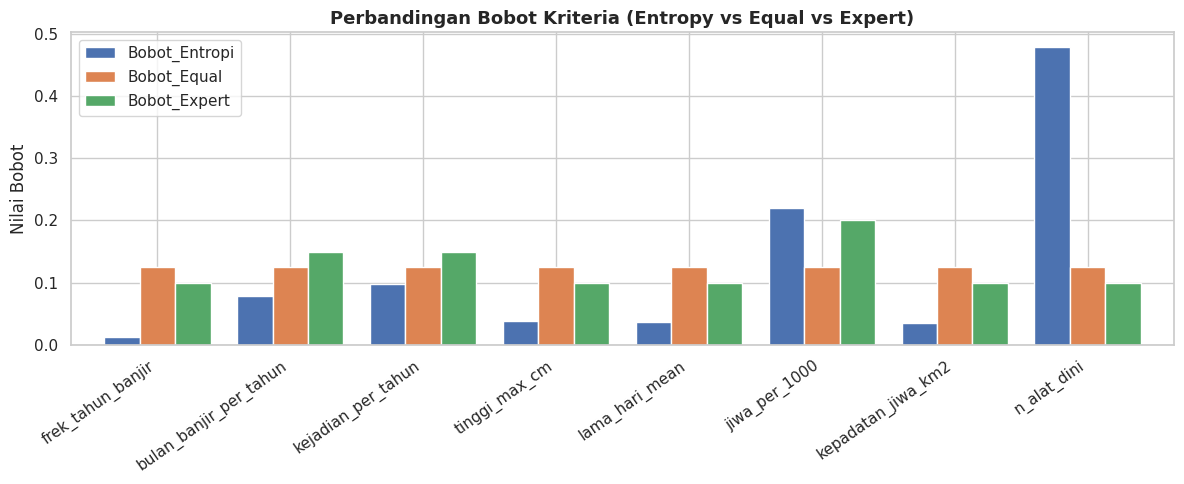

In [4]:
# 1. Bobot Entropi Shannon
eps = 1e-12
m, n = X.shape
col_sums = X.sum(axis=0, keepdims=True)
P = X / (col_sums + eps)
P = np.where(P <= 0, eps, P)

k_entropy = 1.0 / np.log(m)
E = -k_entropy * np.sum(P * np.log(P), axis=0)
d = 1.0 - E
w_entropy = d / d.sum()

# 2. Bobot Setara (Equal Weights - Baseline)
w_equal = np.ones(n) / n

# 3. Bobot Pakar / Domain Expert (Asumsi Prioritas Kebencanaan)
# Memberikan porsi lebih besar pada dampak manusia (jiwa terdampak) dan frekuensi kejadian
w_expert = np.array([0.10, 0.15, 0.15, 0.10, 0.10, 0.20, 0.10, 0.10])
w_expert = w_expert / w_expert.sum()

weights_df = pd.DataFrame({
    "Dimensi": [criteria_meta[c]["dimensi"] for c in crit_cols],
    "Tipe": crit_types,
    "Bobot_Entropi": np.round(w_entropy, 4),
    "Bobot_Equal": np.round(w_equal, 4),
    "Bobot_Expert": np.round(w_expert, 4)
}, index=crit_cols)

display(weights_df)

# Visualisasi Komparasi Bobot
fig, ax = plt.subplots(figsize=(12, 5))
weights_df[["Bobot_Entropi", "Bobot_Equal", "Bobot_Expert"]].plot.bar(ax=ax, width=0.8)
ax.set_title("Perbandingan Bobot Kriteria (Entropy vs Equal vs Expert)", fontsize=13, fontweight="bold")
ax.set_ylabel("Nilai Bobot")
ax.set_xticklabels(crit_cols, rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 4. Eksekusi Algoritma TOPSIS Murni Step-by-Step

Mari kita jalankan 5 langkah matematis TOPSIS secara bertahap.

In [5]:
# Langkah 1: Normalisasi Vektor
norm_v = np.sqrt(np.sum(X**2, axis=0, keepdims=True))
R = X / (norm_v + eps)
print("Contoh Matriks Normalisasi Vektor R (5 baris pertama):")
display(pd.DataFrame(R[:5], columns=crit_cols, index=df_kec.kecamatan[:5]).round(4))

# Langkah 2: Matriks Ternormalisasi Terbobot (menggunakan Bobot Entropi)
V = R * w_entropy
print("Contoh Matriks Ternormalisasi Terbobot V (5 baris pertama):")
display(pd.DataFrame(V[:5], columns=crit_cols, index=df_kec.kecamatan[:5]).round(4))

Contoh Matriks Normalisasi Vektor R (5 baris pertama):


,frek_tahun_banjir,bulan_banjir_per_tahun,kejadian_per_tahun,tinggi_max_cm,lama_hari_mean,jiwa_per_1000,kepadatan_jiwa_km2,n_alat_dini
kecamatan,,,,,,,,
CENGKARENG,0.1772,0.2070,0.2589,0.1564,0.2003,0.5507,0.1421,0.4588
GROGOL PETAMBURAN,0.1772,0.1114,0.1080,0.1173,0.1975,0.0207,0.1393,0.0000
KALI DERES,0.1772,0.1327,0.1182,0.1564,0.1453,0.0442,0.0926,0.0000
KEBON JERUK,0.1772,0.2282,0.2650,0.1251,0.1370,0.3560,0.1325,0.0000
KEMBANGAN,0.1772,0.2123,0.1712,0.1408,0.0869,0.1703,0.0799,0.2294


Contoh Matriks Ternormalisasi Terbobot V (5 baris pertama):


,frek_tahun_banjir,bulan_banjir_per_tahun,kejadian_per_tahun,tinggi_max_cm,lama_hari_mean,jiwa_per_1000,kepadatan_jiwa_km2,n_alat_dini
kecamatan,,,,,,,,
CENGKARENG,0.0023,0.0164,0.0253,0.0059,0.0074,0.1215,0.0051,0.2195
GROGOL PETAMBURAN,0.0023,0.0088,0.0106,0.0044,0.0073,0.0046,0.0050,0.0000
KALI DERES,0.0023,0.0105,0.0116,0.0059,0.0053,0.0097,0.0033,0.0000
KEBON JERUK,0.0023,0.0181,0.0259,0.0047,0.0050,0.0785,0.0048,0.0000
KEMBANGAN,0.0023,0.0168,0.0168,0.0053,0.0032,0.0376,0.0029,0.1098


In [6]:
# Langkah 3: Menentukan Solusi Ideal Positif (A+) dan Solusi Ideal Negatif (A-)
A_pos = np.zeros(n)
A_neg = np.zeros(n)

for j, c_type in enumerate(crit_types):
    if c_type == "benefit":
        A_pos[j] = np.max(V[:, j])
        A_neg[j] = np.min(V[:, j])
    else:  # cost (n_alat_dini)
        A_pos[j] = np.min(V[:, j])
        A_neg[j] = np.max(V[:, j])

ideal_df = pd.DataFrame({"Ideal_Positif_A+": A_pos, "Ideal_Negatif_A-": A_neg}, index=crit_cols)
print("Solusi Ideal Positif dan Negatif:")
display(ideal_df.round(5))

# Langkah 4: Jarak Euclidean ke Solusi Ideal
D_pos = np.sqrt(np.sum((V - A_pos)**2, axis=1))
D_neg = np.sqrt(np.sum((V - A_neg)**2, axis=1))

# Langkah 5: Nilai Preferensi / Kedekatan Relatif (Ci)
Ci = D_neg / (D_pos + D_neg + eps)

df_kec["skor_topsis"] = Ci
df_kec["D_pos"] = D_pos
df_kec["D_neg"] = D_neg
df_kec["rank_topsis"] = df_kec["skor_topsis"].rank(ascending=False).astype(int)

print("Kalkulasi TOPSIS Murni dengan Bobot Entropi Selesai!")

Solusi Ideal Positif dan Negatif:


,Ideal_Positif_A+,Ideal_Negatif_A-
frek_tahun_banjir,0.00233,0.00058
bulan_banjir_per_tahun,0.02737,0.00084
kejadian_per_tahun,0.03613,0.00080
tinggi_max_cm,0.01186,0.00119
lama_hari_mean,0.01343,0.00000
jiwa_per_1000,0.12147,0.00000
kepadatan_jiwa_km2,0.01428,0.00205
n_alat_dini,0.00000,0.21952


Kalkulasi TOPSIS Murni dengan Bobot Entropi Selesai!


## 5. Analisis Sensitivitas (Sensitivity Analysis)

Untuk memastikan keandalan hasil, kita menghitung peringkat TOPSIS dengan skema alternatif:
1. **TOPSIS - Bobot Entropi** (Objektif berbasis variabilitas data)
2. **TOPSIS - Bobot Setara / Equal** (Semua kriteria berbobot $1/n$)
3. **TOPSIS - Bobot Pakar / Expert** (Berbobot tinggi pada korban jiwa & frekuensi kejadian)

Tingkat kestabilan peringkat dievaluasi menggunakan **Korelasi Rank Spearman ($\rho$)**.

In [7]:
def hitung_topsis(X_mat, weights, types):
    norm_ = np.sqrt(np.sum(X_mat**2, axis=0, keepdims=True))
    R_ = X_mat / (norm_ + 1e-12)
    V_ = R_ * weights
    a_p = np.zeros(len(types))
    a_n = np.zeros(len(types))
    for idx, t in enumerate(types):
        if t == "benefit":
            a_p[idx] = np.max(V_[:, idx]); a_n[idx] = np.min(V_[:, idx])
        else:
            a_p[idx] = np.min(V_[:, idx]); a_n[idx] = np.max(V_[:, idx])
    d_p = np.sqrt(np.sum((V_ - a_p)**2, axis=1))
    d_n = np.sqrt(np.sum((V_ - a_n)**2, axis=1))
    return d_n / (d_p + d_n + 1e-12)

# Hitung skor untuk Equal dan Expert
df_kec["skor_equal"] = hitung_topsis(X, w_equal, crit_types)
df_kec["rank_equal"] = df_kec["skor_equal"].rank(ascending=False).astype(int)

df_kec["skor_expert"] = hitung_topsis(X, w_expert, crit_types)
df_kec["rank_expert"] = df_kec["skor_expert"].rank(ascending=False).astype(int)

# Hitung Korelasi Spearman
rho_eq, _ = spearmanr(df_kec["rank_topsis"], df_kec["rank_equal"])
rho_exp, _ = spearmanr(df_kec["rank_topsis"], df_kec["rank_expert"])

print(f"Korelasi Peringkat Spearman:")
print(f"  - Entropi vs Equal  : rho = {rho_eq:.3f}")
print(f"  - Entropi vs Expert : rho = {rho_exp:.3f}")

Korelasi Peringkat Spearman:
  - Entropi vs Equal  : rho = 0.301
  - Entropi vs Expert : rho = 0.037


## 6. Analisis Hasil Perankingan Risiko Banjir

Berikut adalah **Top 15 Kecamatan dengan Prioritas Mitigasi Tertinggi** di DKI Jakarta berdasarkan TOPSIS Murni.

,rank_topsis,kecamatan,wilayah,skor_topsis,rank_equal,rank_expert,jiwa_per_1000,kejadian_per_tahun,n_alat_dini
0,1,KEBON JERUK,JAKARTA BARAT,0.832322,1,3,53.463331,16.250,0.0
1,2,TANJUNG PRIOK,JAKARTA UTARA,0.717263,7,8,27.425273,7.625,0.0
2,3,TANAH ABANG,JAKARTA PUSAT,0.707320,10,11,26.010408,3.125,0.0
3,4,PENJARINGAN,JAKARTA UTARA,0.692689,6,7,17.037983,16.500,0.0
4,5,CILANDAK,JAKARTA SELATAN,0.685469,8,10,15.663835,10.875,0.0
5,6,SAWAH BESAR,JAKARTA PUSAT,0.674210,31,28,16.850182,1.750,0.0
6,7,PALMERAH,JAKARTA BARAT,0.674144,22,22,15.282375,3.750,0.0
7,8,CILINCING,JAKARTA UTARA,0.666021,15,16,10.218233,10.125,0.0
8,9,MAMPANG PRAPATAN,JAKARTA SELATAN,0.664510,13,13,9.061451,10.750,0.0
9,10,PESANGGRAHAN,JAKARTA SELATAN,0.663929,12,15,9.356011,8.000,0.0


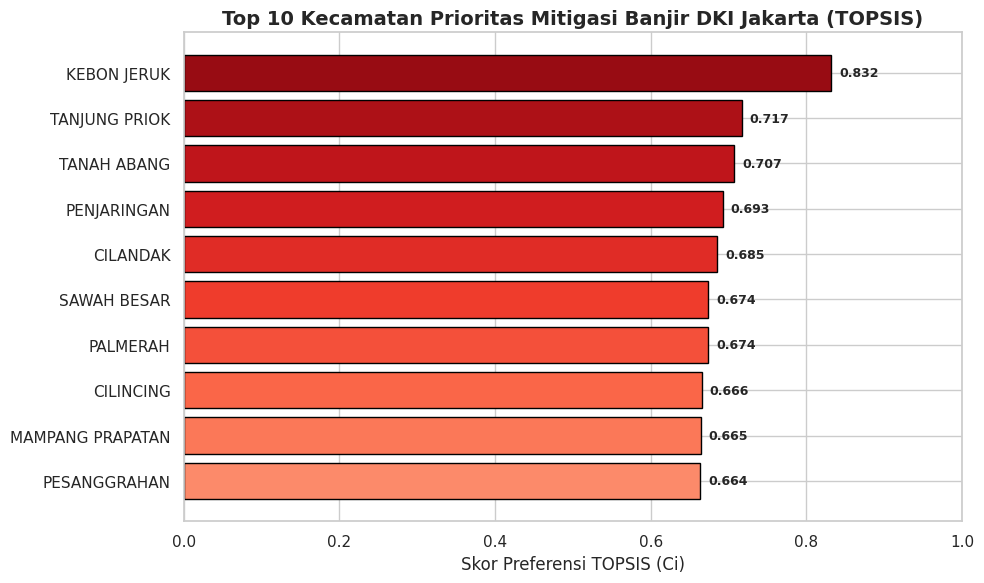

In [8]:
top_ranking = df_kec.sort_values("rank_topsis")[
    ["rank_topsis", "kecamatan", "wilayah", "skor_topsis", "rank_equal", "rank_expert", "jiwa_per_1000", "kejadian_per_tahun", "n_alat_dini"]
].reset_index(drop=True)

display(top_ranking.head(15))

# Visualisasi Top 10 Kecamatan
fig, ax = plt.subplots(figsize=(10, 6))
plot_top = top_ranking.head(10).sort_values("skor_topsis", ascending=True)
colors = plt.cm.Reds(np.linspace(0.4, 0.9, len(plot_top)))

bars = ax.barh(plot_top["kecamatan"], plot_top["skor_topsis"], color=colors, edgecolor="black")
ax.set_title("Top 10 Kecamatan Prioritas Mitigasi Banjir DKI Jakarta (TOPSIS)", fontsize=14, fontweight="bold")
ax.set_xlabel("Skor Preferensi TOPSIS (Ci)")
ax.set_xlim(0, 1.0)

for bar in bars:
    w = bar.get_width()
    ax.annotate(f"{w:.3f}", xy=(w + 0.01, bar.get_y() + bar.get_height() / 2),
                va="center", ha="left", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

## 7. Visualisasi Peta Spasial Skor Risiko TOPSIS

Kita memetakan nilai skor TOPSIS ke poligon wilayah kecamatan menggunakan `kecamatan_poly.geojson` dari `Data/interim/`.

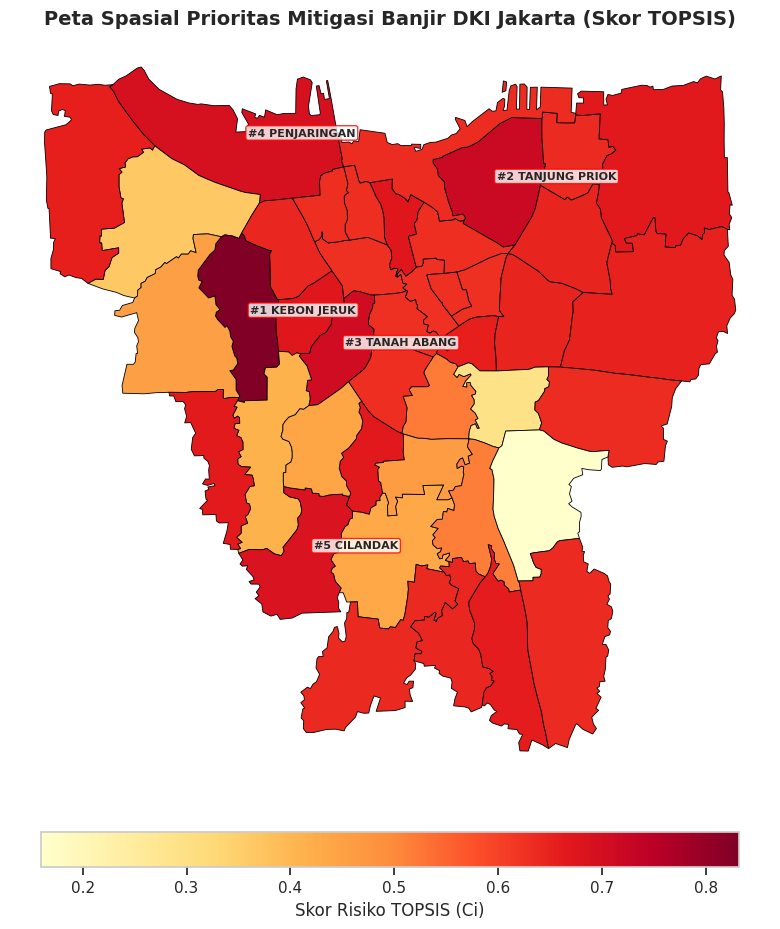

In [9]:
poly_file = INT / "kecamatan_poly.geojson"
if poly_file.exists():
    gdf = gpd.read_file(poly_file)
    gdf_map = gdf.merge(df_kec[["kecamatan", "skor_topsis", "rank_topsis"]], on="kecamatan", how="inner")
    
    fig, ax = plt.subplots(figsize=(12, 10))
    gdf_map.plot(
        column="skor_topsis",
        cmap="YlOrRd",
        legend=True,
        legend_kwds={"label": "Skor Risiko TOPSIS (Ci)", "orientation": "horizontal", "shrink": 0.6, "pad": 0.05},
        edgecolor="black",
        linewidth=0.6,
        ax=ax
    )
    
    # Beri anotasi nama kecamatan untuk 5 ranking teratas
    top5 = gdf_map.sort_values("rank_topsis").head(5)
    for _, row in top5.iterrows():
        pt = row["geometry"].representative_point()
        ax.annotate(
            f"#{row['rank_topsis']} {row['kecamatan']}",
            xy=(pt.x, pt.y),
            xytext=(3, 3),
            textcoords="offset points",
            fontsize=8,
            fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.8, edgecolor="red")
        )
        
    ax.set_title("Peta Spasial Prioritas Mitigasi Banjir DKI Jakarta (Skor TOPSIS)", fontsize=14, fontweight="bold")
    ax.set_axis_off()
    plt.tight_layout()
    plt.show()
else:
    print("File kecamatan_poly.geojson tidak ditemukan, lewati pembuatan peta spasial.")

## 7b. Skema Pembanding: TOPSIS 6 Kriteria (Banjir & Kepadatan)

Untuk mendukung fleksibilitas pemodelan rekan tim pada tahap K-Means, kita juga menghitung skor TOPSIS menggunakan **6 Kriteria Inti Banjir & Kepadatan** (sebagaimana tercantum dalam dokumentasi `README.md`):
- `frek_tahun_banjir`, `bulan_banjir_per_tahun`, `kejadian_per_tahun`, `tinggi_max_cm`, `jiwa_per_1000`, `kepadatan_jiwa_km2` (semua kriteria bertipe *benefit*).

In [10]:
crit_6 = ["frek_tahun_banjir", "bulan_banjir_per_tahun", "kejadian_per_tahun", "tinggi_max_cm", "jiwa_per_1000", "kepadatan_jiwa_km2"]
X6 = df_kec[crit_6].values.astype(float)
P6 = X6 / (X6.sum(axis=0, keepdims=True) + 1e-12)
P6 = np.where(P6 <= 0, 1e-12, P6)
k6 = 1.0 / np.log(len(X6))
E6 = -k6 * np.sum(P6 * np.log(P6), axis=0)
w6 = (1.0 - E6) / (1.0 - E6).sum()

ci_6 = hitung_topsis(X6, w6, ["benefit"] * 6)
df_kec["skor_topsis_6kriteria"] = ci_6
df_kec["rank_topsis_6kriteria"] = df_kec["skor_topsis_6kriteria"].rank(ascending=False).astype(int)

print("Top 5 Kecamatan (Skema 6 Kriteria Banjir & Kepadatan):")
display(df_kec.sort_values("rank_topsis_6kriteria")[["rank_topsis_6kriteria", "kecamatan", "wilayah", "skor_topsis_6kriteria", "rank_topsis", "skor_topsis"]].head(5))

Top 5 Kecamatan (Skema 6 Kriteria Banjir & Kepadatan):


,rank_topsis_6kriteria,kecamatan,wilayah,skor_topsis_6kriteria,rank_topsis,skor_topsis
0,1,CENGKARENG,JAKARTA BARAT,0.868990,40,0.362360
30,2,JATINEGARA,JAKARTA TIMUR,0.686642,41,0.291639
3,3,KEBON JERUK,JAKARTA BARAT,0.644002,1,0.832322
25,4,TEBET,JAKARTA SELATAN,0.584365,33,0.522102
31,5,KRAMAT JATI,JAKARTA TIMUR,0.554496,34,0.514963


## 8. Ekspor Hasil Analisis TOPSIS

Hasil lengkap disimpan ke `Data/topsis_result.csv`.  
Dataset ini memuat:
- Seluruh fitur master kecamatan
- Skor preferensi TOPSIS utama (`skor_topsis`, `rank_topsis`)
- Skor preferensi pembanding 6 kriteria (`skor_topsis_6kriteria`, `rank_topsis_6kriteria`)
- Nilai jarak euclidean ke solusi ideal ($D^+$, $D^-$)
- Hasil variasi bobot pembanding (`skor_equal`, `rank_equal`, `skor_expert`, `rank_expert`)

File ini dapat langsung digunakan sebagai input oleh rekan tim yang mengerjakan clustering K-Means (`03_kmeans.ipynb`).

In [11]:
out_file = DATA / "topsis_result.csv"
df_kec.to_csv(out_file, index=False)
print(f"Hasil TOPSIS berhasil disimpan ke: {out_file.resolve()}")
print(f"Ukuran data: {df_kec.shape[0]} baris x {df_kec.shape[1]} kolom")
print("\nKolom hasil perhitungan TOPSIS:")
print([col for col in df_kec.columns if "topsis" in col or "equal" in col or "expert" in col or col.startswith("D_")])

Hasil TOPSIS berhasil disimpan ke: C:\Sem5_Projects\Geopulse-id\Data\topsis_result.csv
Ukuran data: 42 baris x 30 kolom

Kolom hasil perhitungan TOPSIS:
['skor_topsis', 'D_pos', 'D_neg', 'rank_topsis', 'skor_equal', 'rank_equal', 'skor_expert', 'rank_expert', 'skor_topsis_6kriteria', 'rank_topsis_6kriteria']
